# 05 · Comparación de modelos, errores e interpretabilidad — Sprint 3

**Responsable:** Joan · **Plan:** `project_plan_crisp_dm.md` §8.1–8.3 y §7.3 · **Entradas:** los modelos de las fichas 4 y 7 (Joan), 9–10 (Pardo), 12–13 (José) y 14 (AutoML con FLAML).

**Regla de este notebook:** todo con **solo train** y `TimeSeriesSplit` (`get_cv()`). El test (jul–dic 2012) no se carga y **no se reentrena ningún modelo con todo train**: los modelos se ajustan dentro de cada fold. Las predicciones usadas para analizar errores son **fuera de muestra** (las de la ventana de validación de cada fold). La **elección del modelo final es una propuesta** (sección 8); la decide Joan.

**Estado de las afirmaciones:** se indica si cada afirmación está verificada con el código de este notebook, es una hipótesis o está pendiente.


## 1) Preparación del entorno y datos

In [1]:
import sys, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from lightgbm import LGBMRegressor
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "config" / "config.py").exists():
        RAIZ = _p
        break
else:
    raise FileNotFoundError("No se encontró config/config.py")
sys.path.insert(0, str(RAIZ))

from config.config import CONFIG, RANDOM_STATE
from src.data_loader import load_data, temporal_split, separar_xy
from src.features import build_preprocessor, agregar_lags
from src.evaluate import (rmsle, ajustar, predecir_bicis, calcular_metricas, get_cv, validar_temporal)
from src.lineales import PrepLineal
from src.clustering import build_clustering, K_ELEGIDO, VARIABLES

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
FIG_DIR = CONFIG["dir_reports"] / "joan" / "figuras"; FIG_DIR.mkdir(parents=True, exist_ok=True)
def guardar(fig, nombre): fig.savefig(FIG_DIR / f"{nombre}.png", dpi=130, bbox_inches="tight")

df = load_data()
train, test = temporal_split(df)
del test                                           # el test no se usa en este notebook
X_tr, y_tr = separar_xy(train)
X_l, y_l = separar_xy(temporal_split(agregar_lags(df))[0])
LAGS = CONFIG["lgbm"]["lags"]
cv0, cv24 = get_cv(), get_cv(gap=CONFIG["lgbm"]["gap_con_lags"])
print("Train:", X_tr.shape, "| rango:", X_tr.index.min(), "->", X_tr.index.max())
print("Con lags:", X_l.shape, "| columnas lag:", [c for c in X_l.columns if c.startswith("lag_")])
print("Validación sin lags:", cv0, "\nValidación con lags:", cv24)

Train: (13003, 13) | rango: 2011-01-01 00:00:00 -> 2012-06-30 23:00:00
Con lags: (13003, 15) | columnas lag: ['lag_24', 'lag_168']
Validación sin lags: TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=1460) 
Validación con lags: TimeSeriesSplit(gap=24, max_train_size=None, n_splits=5, test_size=1460)


### Punto de control 1: sin test y con las mismas filas en las dos vías

In [2]:
assert RANDOM_STATE == 42
assert X_tr.index.max() <= pd.Timestamp(CONFIG["ultima_hora_train"])
assert X_tr.index.equals(X_l.index) and np.allclose(y_tr, y_l)
assert not {"cnt", "casual", "registered", "instant"} & set(X_tr.columns)
# Las ventanas de validación son las mismas filas con y sin gap (el gap solo recorta el final del train)
va0 = [i_va for _, i_va in cv0.split(X_tr)]; va24 = [i_va for _, i_va in cv24.split(X_tr)]
assert all((a == b).all() for a, b in zip(va0, va24))
vent = pd.DataFrame([{"fold": k, "desde": X_tr.index[v[0]], "hasta": X_tr.index[v[-1]], "n": len(v)} for k, v in enumerate(va0, 1)])
display(vent)
print(" Test no cargado; X con y sin lags tiene las mismas 13 003 filas; validaciones comparables.")

,fold,desde,hasta,n
0,1,2011-08-31 02:00:00,2011-10-31 01:00:00,1460
1,2,2011-10-31 02:00:00,2011-12-31 01:00:00,1460
2,3,2011-12-31 02:00:00,2012-03-01 04:00:00,1460
3,4,2012-03-01 05:00:00,2012-05-01 03:00:00,1460
4,5,2012-05-01 04:00:00,2012-06-30 23:00:00,1460


 Test no cargado; X con y sin lags tiene las mismas 13 003 filas; validaciones comparables.


## 2) Los modelos, reconstruidos con código

Cada modelo se arma con las configuraciones registradas en `reports/decisiones.md`; **nada se copia de las tablas de los resúmenes**. Para AutoML no se repite la búsqueda de FLAML (su resultado cambia entre ejecuciones por depender del tiempo de cómputo): se toma la **configuración ganadora** de `reports/jose/automl_config.json` y se construye el `LGBMRegressor` equivalente. Si reproduce el RMSLE que José guardó en ese JSON, es el mismo modelo.

In [3]:
RES_JOSE = CONFIG["dir_reports"] / "jose"
cfg_automl = json.load(open(RES_JOSE / "automl_config.json", encoding="utf-8"))
ref_csv = pd.read_csv(RES_JOSE / "automl_comparacion.csv")

def lgbm_desde_flaml(config):
    """LGBMRegressor equivalente al que FLAML devuelve para `config` (max_bin = 2**log_max_bin - 1)."""
    c = dict(config); log_max_bin = c.pop("log_max_bin")
    return LGBMRegressor(max_bin=(1 << int(round(log_max_bin))) - 1, n_jobs=-1, verbose=-1, **c)

class MediaPorGrupo(BaseEstimator, RegressorMixin):
    """Baseline (§6.1): media de cnt por (hr, workingday), aprendida en fit con el train del fold."""
    def fit(self, X, y):
        d = pd.DataFrame({"hr": X["hr"].to_numpy(), "workingday": X["workingday"].to_numpy(), "y": np.asarray(y, dtype=float)})
        self.medias_ = d.groupby(["hr", "workingday"])["y"].mean(); self.media_global_ = float(d["y"].mean()); return self
    def predict(self, X):
        k = pd.MultiIndex.from_arrays([X["hr"].to_numpy(), X["workingday"].to_numpy()])
        return self.medias_.reindex(k).fillna(self.media_global_).to_numpy()

P_LGBM = {**CONFIG["lgbm"]["params_base"], **CONFIG["lgbm"]["params_tuneados"]}            # ficha 4
P_RF = dict(n_estimators=300, max_features=0.5, min_samples_leaf=1, max_depth=25)            # ficha 12

def construir(modelo, lags):
    """Devuelve (pipeline, log_target) para `modelo` con o sin lags."""
    lg = tuple(LAGS) if lags else ()
    if modelo == "Baseline (hr, workingday)":
        return MediaPorGrupo(), False
    if modelo == "Ridge (splines × temp)":
        return Pipeline([("prep", PrepLineal(codif_hora="splines", interaccion_temp=True, lags=lg)), ("modelo", Ridge(alpha=1.0))]), True
    if modelo == "Random Forest":
        return Pipeline([("prep", build_preprocessor(lags=lg)), ("modelo", RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE, **P_RF))]), True
    if modelo == "LightGBM manual":
        return Pipeline([("prep", build_preprocessor(lags=lg)), ("modelo", LGBMRegressor(**P_LGBM))]), True
    if modelo == "AutoML (FLAML → lgbm)":
        cfg = cfg_automl["con_lags" if lags else "sin_lags"]["mejor_config"]
        return Pipeline([("prep", build_preprocessor(lags=lg)), ("modelo", lgbm_desde_flaml(cfg))]), True
    raise ValueError(modelo)

MODELOS = ["Baseline (hr, workingday)", "Ridge (splines × temp)", "Random Forest", "LightGBM manual", "AutoML (FLAML → lgbm)"]
print("Parámetros LightGBM manual:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in P_LGBM.items() if k in CONFIG['lgbm']['params_tuneados']})
print("Parámetros AutoML sin lags:", cfg_automl["sin_lags"]["mejor_config"])
print("Parámetros AutoML con lags:", cfg_automl["con_lags"]["mejor_config"])

Parámetros LightGBM manual: {'n_estimators': 524, 'learning_rate': 0.0462, 'num_leaves': 31, 'min_child_samples': 81, 'colsample_bytree': 0.8767, 'reg_lambda': 0.2857}
Parámetros AutoML sin lags: {'n_estimators': 2027, 'num_leaves': 4, 'min_child_samples': 18, 'learning_rate': 0.07995219129498729, 'log_max_bin': 8, 'colsample_bytree': 0.7654968621694198, 'reg_alpha': 2.8061780535782885, 'reg_lambda': 0.1253123456265875}
Parámetros AutoML con lags: {'n_estimators': 185, 'num_leaves': 55, 'min_child_samples': 37, 'learning_rate': 0.060242945539396214, 'log_max_bin': 7, 'colsample_bytree': 0.4215996970619771, 'reg_alpha': 0.9877451927935172, 'reg_lambda': 0.45517499954285745}


### Ajuste fuera de muestra
Para cada modelo y cada fold: se clona el pipeline, se ajusta **solo con el train del fold** y se predice la ventana de validación. Se guardan las predicciones (en bicicletas) para el análisis de errores.

In [4]:
def oof(pipe, X, y, cv_, log_target):
    """Predicciones fuera de muestra: una fila por hora de validación, con su fold. Devuelve (DataFrame, segundos)."""
    y = np.asarray(y, dtype=float); partes = []; t0 = time.perf_counter()
    for k, (i_tr, i_va) in enumerate(cv_.split(X), start=1):
        m = ajustar(clone(pipe), X.iloc[i_tr], y[i_tr], log_target)
        partes.append(pd.DataFrame({"fold": k, "y": y[i_va], "pred": predecir_bicis(m, X.iloc[i_va], log_target)}, index=X.index[i_va]))
    return pd.concat(partes), time.perf_counter() - t0

def tabla_folds(o):
    return pd.DataFrame([{"fold": k, **calcular_metricas(g["y"], g["pred"])} for k, g in o.groupby("fold")]).set_index("fold")

OOF, TIEMPO = {}, {}
for via, X, cv_, lags in [("Sin lags (gap=0)", X_tr, cv0, False), ("Con lags (gap=24)", X_l, cv24, True)]:
    for nombre in MODELOS:
        pipe, log_t = construir(nombre, lags)
        OOF[(via, nombre)], TIEMPO[(via, nombre)] = oof(pipe, X, y_tr, cv_, log_t)
        print(f"{via:18s} {nombre:26s} RMSLE medio = {tabla_folds(OOF[(via, nombre)])['rmsle'].mean():.4f}  ({TIEMPO[(via, nombre)]:.1f} s)")

Sin lags (gap=0)   Baseline (hr, workingday)  RMSLE medio = 0.5585  (0.0 s)


Sin lags (gap=0)   Ridge (splines × temp)     RMSLE medio = 0.4885  (0.2 s)


Sin lags (gap=0)   Random Forest              RMSLE medio = 0.4826  (3.0 s)


Sin lags (gap=0)   LightGBM manual            RMSLE medio = 0.4549  (2.4 s)


Sin lags (gap=0)   AutoML (FLAML → lgbm)      RMSLE medio = 0.4405  (2.6 s)
Con lags (gap=24)  Baseline (hr, workingday)  RMSLE medio = 0.5586  (0.0 s)


Con lags (gap=24)  Ridge (splines × temp)     RMSLE medio = 0.4766  (0.3 s)


Con lags (gap=24)  Random Forest              RMSLE medio = 0.4125  (3.8 s)


Con lags (gap=24)  LightGBM manual            RMSLE medio = 0.3905  (3.3 s)


Con lags (gap=24)  AutoML (FLAML → lgbm)      RMSLE medio = 0.3876  (1.7 s)


### Punto de control 2: coherencia con las evaluaciones anteriores

In [5]:
def rm(via, modelo): return tabla_folds(OOF[(via, modelo)])["rmsle"]
S, C = "Sin lags (gap=0)", "Con lags (gap=24)"

# 1) Mismas filas de validación en todos los modelos y ambas vías
idx0 = OOF[(S, MODELOS[0])].index
assert all(o.index.equals(idx0) for o in OOF.values()) and len(idx0) == 5 * 1460
# 2) Coinciden con lo registrado por cada responsable (tolerancia por redondeo a 4 decimales)
esperado = {(S, "Baseline (hr, workingday)"): 0.5585, (S, "Ridge (splines × temp)"): 0.4885, (S, "Random Forest"): 0.4826,
            (S, "LightGBM manual"): 0.4549, (C, "Ridge (splines × temp)"): 0.4766, (C, "Random Forest"): 0.4125,
            (C, "LightGBM manual"): 0.3905}
for k, v in esperado.items():
    assert abs(rm(*k).mean() - v) < 6e-4, (k, rm(*k).mean(), v)
# 3) AutoML: la configuración reconstruida reproduce el RMSLE guardado en el JSON y los folds del CSV
for via, clave, fila in [(S, "sin_lags", 1), (C, "con_lags", 3)]:
    r = rm(via, "AutoML (FLAML → lgbm)")
    assert abs(r.mean() - cfg_automl[clave]["reevaluacion_rmsle"]) < 1e-6, (via, r.mean(), cfg_automl[clave]["reevaluacion_rmsle"])
    assert np.allclose(r.to_numpy(), ref_csv.loc[fila, ["f1", "f2", "f3", "f4", "f5"]].to_numpy(dtype=float), atol=6e-5)
# 4) Consistencia con validar_temporal para un modelo
pf, rs = validar_temporal(construir("LightGBM manual", False)[0], X_tr, y_tr, "chk", cv=cv0)
assert np.allclose(pf["rmsle"].to_numpy(), rm(S, "LightGBM manual").to_numpy())
print(" Los 5 modelos reproducen lo registrado; AutoML reproduce 0.44045 / 0.38757 de automl_config.json (modelo idéntico).")

 Los 5 modelos reproducen lo registrado; AutoML reproduce 0.44045 / 0.38757 de automl_config.json (modelo idéntico).


**Interpretación.** Los cinco modelos se reconstruyeron con código y reproducen lo que registró cada responsable: baseline 0.5585, Ridge 0.4885, Random Forest 0.4826, LightGBM 0.4549 y AutoML 0.4405 sin lags; Ridge 0.4766, Random Forest 0.4125, LightGBM 0.3905 y AutoML 0.3876 con lags. Para AutoML se verificó lo más delicado: el `LGBMRegressor` construido con la configuración ganadora reproduce el RMSLE de `automl_config.json` con 6 decimales y los cinco RMSLE por fold de `automl_comparacion.csv`, así que es el mismo modelo que evaluó José, sin repetir la búsqueda de FLAML. Dos aclaraciones: (1) la vía con lags usa `gap = 24`, por lo que su baseline da 0.5586 (0.5585 con `gap = 0`); (2) las ventanas de validación son las mismas 7 300 horas en las dos vías (el `gap` solo recorta el final del train).

## 3) Tabla comparativa de validación (§8.1)
Dos vías para una comparación justa: **sin lags** (`gap=0`) y **con lags 24 h y 168 h** (`gap=24`). Tiempo = segundos de ajuste y predicción de los 5 folds en esta máquina (no incluye la búsqueda de hiperparámetros).

In [6]:
filas = []
for via in (S, C):
    r = pd.DataFrame({m: rm(via, m) for m in MODELOS})                  # RMSLE por fold x modelo
    mejor_fold = r.idxmin(axis=1).value_counts()
    for m in MODELOS:
        t = tabla_folds(OOF[(via, m)])
        filas.append({"vía": via, "modelo": m, "RMSLE": t["rmsle"].mean(), "± std folds": t["rmsle"].std(ddof=1), "peor fold": t["rmsle"].max(),
                      "RMSE": t["rmse"].mean(), "MAE": t["mae"].mean(), "R²": t["r2"].mean(),
                      "folds en que es el mejor": int(mejor_fold.get(m, 0)), "tiempo 5 folds (s)": TIEMPO[(via, m)]})
comparativa = pd.DataFrame(filas)
for via in (S, C):
    print(via); display(comparativa[comparativa["vía"] == via].drop(columns="vía").set_index("modelo").round(4))

Sin lags (gap=0)


,RMSLE,± std folds,peor fold,RMSE,MAE,R²,folds en que es el mejor,tiempo 5 folds (s)
modelo,,,,,,,,
"Baseline (hr, workingday)",0.5585,0.0601,0.6286,102.7835,72.3275,0.6193,1,0.0107
Ridge (splines × temp),0.4885,0.1583,0.7489,81.6091,51.8988,0.7011,0,0.2457
Random Forest,0.4826,0.1748,0.7630,79.0669,53.8619,0.7063,0,2.9743
LightGBM manual,0.4549,0.1918,0.7797,70.6015,47.2129,0.7501,1,2.4344
AutoML (FLAML → lgbm),0.4405,0.1946,0.7702,67.1093,44.6274,0.7617,3,2.6305


Con lags (gap=24)


,RMSLE,± std folds,peor fold,RMSE,MAE,R²,folds en que es el mejor,tiempo 5 folds (s)
modelo,,,,,,,,
"Baseline (hr, workingday)",0.5586,0.0601,0.6291,102.8226,72.3606,0.6190,0,0.0179
Ridge (splines × temp),0.4766,0.1335,0.6958,91.5072,56.3211,0.6669,0,0.3424
Random Forest,0.4125,0.0598,0.4690,70.9281,43.8301,0.7952,1,3.8253
LightGBM manual,0.3905,0.0853,0.5044,63.1736,40.6275,0.8243,3,3.3107
AutoML (FLAML → lgbm),0.3876,0.0697,0.4736,64.3518,41.0017,0.8247,1,1.6513


### Punto de control 3

In [7]:
assert comparativa["RMSLE"].notna().all() and len(comparativa) == 10
for via in (S, C):
    assert comparativa[comparativa["vía"] == via]["folds en que es el mejor"].sum() == 5
base = comparativa.query("modelo == 'Baseline (hr, workingday)'").set_index("vía")["RMSLE"]
assert (comparativa.query("modelo != 'Baseline (hr, workingday)'")["RMSLE"] < base[S]).all(), "todos los modelos deberían superar al baseline sin lags"
print(" Tabla completa; cada fold tiene un único mejor modelo; todos superan al baseline.")

 Tabla completa; cada fold tiene un único mejor modelo; todos superan al baseline.


### 3.1 Fold a fold: ¿cuántos folds gana cada modelo a cada otro?

Sin lags (gap=0) - RMSLE por fold


,"Baseline (hr, workingday)",Ridge (splines × temp),Random Forest,LightGBM manual,AutoML (FLAML → lgbm)
fold,,,,,
1,0.4960,0.3821,0.3780,0.3709,0.3732
2,0.5902,0.5243,0.4544,0.4394,0.4366
3,0.4949,0.7489,0.7630,0.7797,0.7702
4,0.5826,0.4235,0.5113,0.4090,0.3599
5,0.6286,0.3638,0.3063,0.2754,0.2623


Folds (de 5) en que la FILA es mejor que la COLUMNA:


,"Baseline (hr, workingday)",Ridge (splines × temp),Random Forest,LightGBM manual,AutoML (FLAML → lgbm)
"Baseline (hr, workingday)",NaN,1.0,1.0,1.0,1.0
Ridge (splines × temp),4.0,NaN,2.0,1.0,1.0
Random Forest,4.0,3.0,NaN,1.0,1.0
LightGBM manual,4.0,4.0,4.0,NaN,1.0
AutoML (FLAML → lgbm),4.0,4.0,4.0,4.0,NaN


Con lags (gap=24) - RMSLE por fold


,"Baseline (hr, workingday)",Ridge (splines × temp),Random Forest,LightGBM manual,AutoML (FLAML → lgbm)
fold,,,,,
1,0.4964,0.3810,0.4176,0.3751,0.3943
2,0.5905,0.5031,0.4690,0.4374,0.4234
3,0.4949,0.6958,0.4595,0.5044,0.4736
4,0.5819,0.4338,0.3967,0.3572,0.3581
5,0.6291,0.3693,0.3195,0.2782,0.2885


Folds (de 5) en que la FILA es mejor que la COLUMNA:


,"Baseline (hr, workingday)",Ridge (splines × temp),Random Forest,LightGBM manual,AutoML (FLAML → lgbm)
"Baseline (hr, workingday)",NaN,1.0,0.0,1.0,0.0
Ridge (splines × temp),4.0,NaN,1.0,0.0,1.0
Random Forest,5.0,4.0,NaN,1.0,1.0
LightGBM manual,4.0,5.0,4.0,NaN,3.0
AutoML (FLAML → lgbm),5.0,4.0,4.0,2.0,NaN


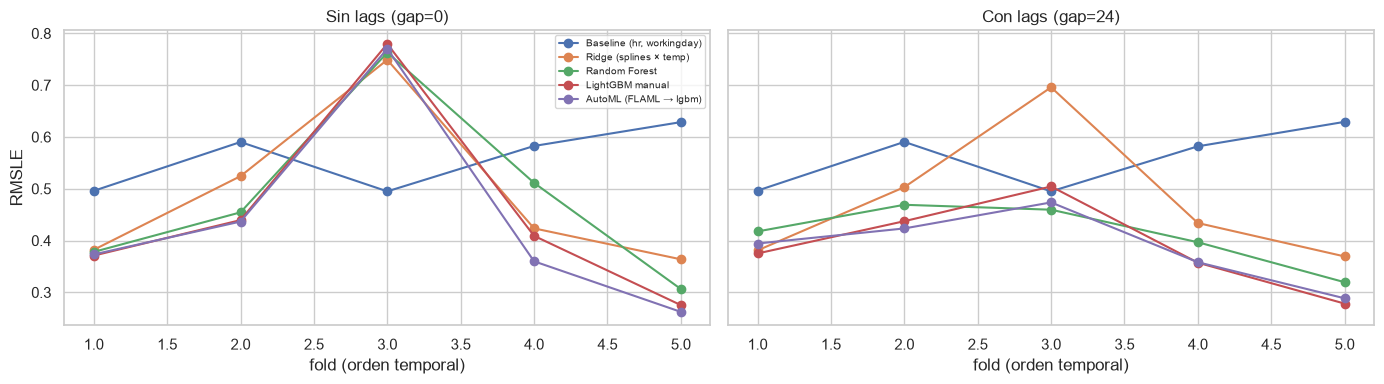

In [8]:
for via in (S, C):
    r = pd.DataFrame({m: rm(via, m) for m in MODELOS}); r.index.name = "fold"
    print(via, "- RMSLE por fold"); display(r.round(4))
    gana = pd.DataFrame({a: {b: int((r[a] < r[b]).sum()) if a != b else np.nan for b in MODELOS} for a in MODELOS}).T
    print("Folds (de 5) en que la FILA es mejor que la COLUMNA:"); display(gana)

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for a, via in zip(ax, (S, C)):
    for m in MODELOS: a.plot(range(1, 6), rm(via, m).to_numpy(), marker="o", label=m)
    a.set_title(via); a.set_xlabel("fold (orden temporal)")
ax[0].set_ylabel("RMSLE"); ax[0].legend(fontsize=7); plt.tight_layout(); guardar(fig, "10_comparativa_por_fold"); plt.show()

### 3.2 ¿Los dos finalistas se distinguen? Diferencia fold a fold y *bootstrap* por bloques de días (§8.2)
Finalistas: **LightGBM manual** y **AutoML** (mismo algoritmo, distinta configuración). Se resume la diferencia por fold y se estima su incertidumbre remuestreando **días completos** (bloques de 24 h, para respetar la dependencia horaria) sobre las predicciones fuera de muestra, 2 000 réplicas y semilla 42. La métrica del bootstrap es el RMSLE *agrupado* de todas las horas de validación (no la media de folds).

In [9]:
def err_log(o): return np.log1p(o["y"].to_numpy()) - np.log1p(o["pred"].to_numpy())

def bootstrap_dias(oa, ob, B=2000, seed=RANDOM_STATE):
    """IC de la diferencia de RMSLE agrupado (a − b) remuestreando días. Negativo = a mejor que b."""
    dia = oa.index.normalize(); dias = np.unique(dia)
    ea, eb = err_log(oa) ** 2, err_log(ob) ** 2
    sa = pd.Series(ea, index=oa.index).groupby(dia).sum().reindex(dias).to_numpy()
    sb = pd.Series(eb, index=oa.index).groupby(dia).sum().reindex(dias).to_numpy()
    n = pd.Series(1, index=oa.index).groupby(dia).sum().reindex(dias).to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(dias), size=(B, len(dias)))
    d = np.sqrt(sa[idx].sum(1) / n[idx].sum(1)) - np.sqrt(sb[idx].sum(1) / n[idx].sum(1))
    return float(np.sqrt(sa.sum() / n.sum()) - np.sqrt(sb.sum() / n.sum())), np.percentile(d, [2.5, 97.5]), float((d < 0).mean())

FIN = ["LightGBM manual", "AutoML (FLAML → lgbm)"]
filas = []
for via in (S, C):
    a, b = rm(via, FIN[0]).to_numpy(), rm(via, FIN[1]).to_numpy()
    d = a - b                                                           # > 0: AutoML mejor
    puntual, ic, p_a_mejor = bootstrap_dias(OOF[(via, FIN[0])], OOF[(via, FIN[1])])
    filas.append({"vía": via, "dif. por fold (LGBM − AutoML)": np.round(d, 4).tolist(), "media": d.mean(), "std de la dif.": d.std(ddof=1),
                  "AutoML mejor en folds": int((d > 0).sum()), "RMSLE agrupado LGBM − AutoML": puntual,
                  "IC95% bootstrap": (round(float(ic[0]), 4), round(float(ic[1]), 4)), "P(LGBM mejor)": p_a_mejor})
dif = pd.DataFrame(filas).set_index("vía"); display(dif.round(4).T)

vía,Sin lags (gap=0),Con lags (gap=24)
dif. por fold (LGBM − AutoML),"[-0.0023, 0.0028, 0.0094, 0.0491, 0.0131]","[-0.0192, 0.014, 0.0308, -0.0009, -0.0103]"
media,0.0144,0.0029
std de la dif.,0.0203,0.0198
AutoML mejor en folds,4,2
RMSLE agrupado LGBM − AutoML,0.0125,0.0053
IC95% bootstrap,"(0.0077, 0.0175)","(-0.0005, 0.0105)"
P(LGBM mejor),0.0,0.035


### Punto de control 4

In [10]:
for via in (S, C):
    a, b = rm(via, FIN[0]), rm(via, FIN[1])
    assert np.isclose((a - b).mean(), a.mean() - b.mean())
assert abs(dif.loc[S, "media"] - 0.0144) < 6e-4 and abs(dif.loc[C, "media"] - 0.0029) < 6e-4, "las diferencias de José (0.0144 y 0.0029) no se reproducen"
print(" Las diferencias medias reproducen las de José (0.0144 sin lags, 0.0029 con lags).")

 Las diferencias medias reproducen las de José (0.0144 sin lags, 0.0029 con lags).


**Interpretación.**
- **Con lags la jerarquía es nítida:** LightGBM manual 0.3905 y AutoML 0.3876 quedan al frente, Random Forest 0.4125, Ridge 0.4766 y el baseline 0.5586. Sin lags, AutoML (0.4405) < LightGBM (0.4549) < Random Forest (0.4826) < Ridge (0.4885) < baseline (0.5585).
- **El fold 3 decide la media.** Sin lags, el baseline es el **mejor modelo del fold 3** (0.4949 frente a 0.7489–0.7797 de los demás): los modelos con `yr` aprenden solo 2011 y no saben que 2012 es más alto, mientras que la media por `(hr, workingday)` no depende del año y falla menos allí. Con lags, en ese fold gana Random Forest (0.4595), por delante de AutoML (0.4736) y LightGBM (0.5044).
- **Las diferencias entre modelos (≈0.03) son menores que la desviación entre folds (0.06–0.19)**, así que el orden de la media debe leerse con los conteos fold a fold: sin lags, AutoML es el mejor en 3 folds, LightGBM en 1 y el baseline en 1; con lags, LightGBM es el mejor en 3 (folds 1, 4 y 5), AutoML en 1 (fold 2) y Random Forest en 1 (fold 3).
- **Cara a cara entre los finalistas:** sin lags, AutoML gana a LightGBM en 4 de 5 folds; con lags, LightGBM gana en 3 de 5, pero AutoML gana los dos folds de mayor error (2 y 3) y su desviación entre folds es menor (0.0697 frente a 0.0853).
- **Métricas en bicicletas:** con lags AutoML tiene mejor RMSLE (0.3876 frente a 0.3905) pero LightGBM tiene mejor RMSE (63.2 frente a 64.4) y MAE (40.6 frente a 41.0); el R² es prácticamente igual (0.824). Sin lags AutoML es mejor en las cuatro métricas (RMSE 67.1 frente a 70.6, MAE 44.6 frente a 47.2).
- **Tiempos:** todos ajustan los 5 folds en segundos (Ridge 0.2–0.3 s, Random Forest 3.2–3.8 s, LightGBM 2.7–3.3 s, AutoML 1.8–2.8 s). El costo real está en la búsqueda de hiperparámetros: ≈300 s para LightGBM manual (ficha 4) y 302 y 299 s para FLAML (`automl_config.json`).
- **Incertidumbre (bootstrap por días):** sin lags la diferencia agrupada a favor de AutoML es 0.0125 con IC95 % [0.0077, 0.0175]; con lags es 0.0053 con IC95 % [−0.0005, 0.0105], y en 3.5 % de las réplicas LightGBM sale mejor. Hipótesis: los intervalos solo miden la variación entre días dentro de las mismas cinco ventanas; no recogen que las ventanas no son intercambiables (por ejemplo, el fold 3), así que son optimistas.
- **Veredicto:** sin lags AutoML es mejor de forma consistente; con lags hay un **empate práctico** (0.0029 de diferencia en el RMSLE medio) con ligera ventaja de AutoML en estabilidad y de LightGBM en folds ganados.

## 4) Residuos y sesgo con predicciones fuera de muestra (§8.2)
Se analizan los dos finalistas **con lags** (la vía que se perfila para el modelo final) y, como contraste, LightGBM **sin lags**. Residuo en escala log: `e = log1p(y) − log1p(ŷ)`; **e > 0 = el modelo subestima**. Todas las filas son de validación (cada hora aparece una sola vez, en el fold que la valida).

In [11]:
ANALIZADOS = {"LightGBM + lags": (C, "LightGBM manual"), "AutoML + lags": (C, "AutoML (FLAML → lgbm)"), "LightGBM sin lags": (S, "LightGBM manual")}
R = {}
for etiqueta, clave in ANALIZADOS.items():
    o = OOF[clave].copy(); o["e"] = err_log(o); o["pred_log"] = np.log1p(o["pred"]); o["y_log"] = np.log1p(o["y"])
    o["mes"] = o.index.to_period("M"); o["hr"] = X_tr.loc[o.index, "hr"]; o["weekday"] = X_tr.loc[o.index, "weekday"]
    o["holiday"] = X_tr.loc[o.index, "holiday"]; o["adverso"] = X_tr.loc[o.index, "weathersit"] >= 3; o["workingday"] = X_tr.loc[o.index, "workingday"]
    R[etiqueta] = o
    print(f"{etiqueta:18s} sesgo medio del residuo (log) = {o['e'].mean():+.4f} | RMSLE agrupado = {np.sqrt((o['e']**2).mean()):.4f}")

LightGBM + lags    sesgo medio del residuo (log) = +0.1103 | RMSLE agrupado = 0.3978
AutoML + lags      sesgo medio del residuo (log) = +0.1034 | RMSLE agrupado = 0.3925
LightGBM sin lags  sesgo medio del residuo (log) = +0.1879 | RMSLE agrupado = 0.4862


### 4.1 Residuos frente al valor predicho (homocedasticidad)

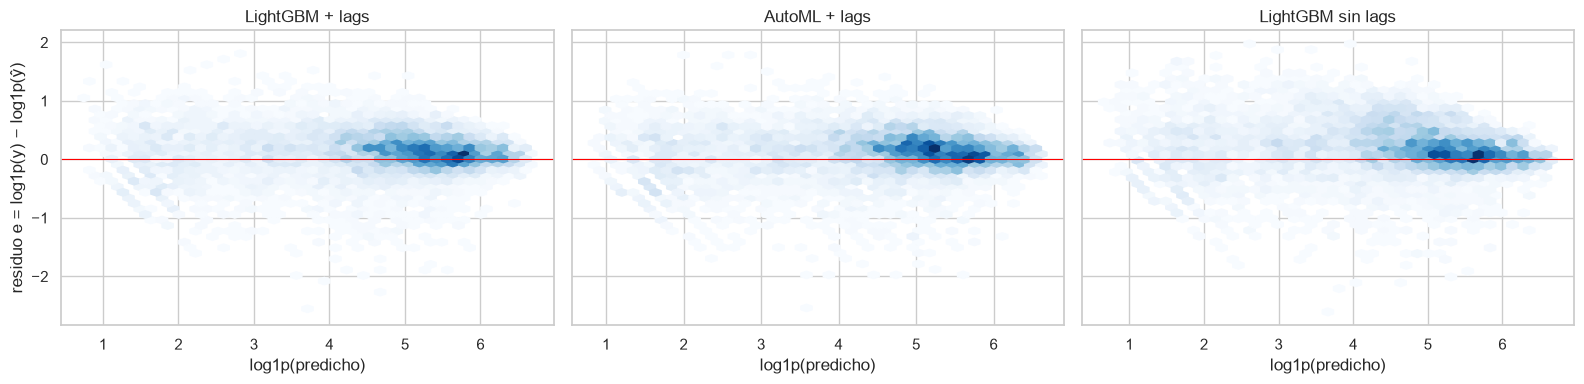

,tramo del predicho (log),n,sesgo (media de e),dispersión (std de e)
0,"(0.746, 2.432]",913,0.080,0.496
1,"(2.432, 3.696]",912,0.139,0.463
2,"(3.696, 4.432]",913,0.137,0.456
3,"(4.432, 4.84]",912,0.134,0.406
4,"(4.84, 5.173]",912,0.148,0.349
5,"(5.173, 5.506]",913,0.083,0.323
6,"(5.506, 5.853]",912,0.081,0.264
7,"(5.853, 6.673]",913,0.079,0.189


Razón entre la mayor y la menor dispersión por tramo: {'LightGBM + lags': np.float64(2.63), 'AutoML + lags': np.float64(2.62), 'LightGBM sin lags': np.float64(2.59)}
Correlación de Spearman entre |e| y el predicho: {'LightGBM + lags': -0.33, 'AutoML + lags': -0.314, 'LightGBM sin lags': -0.355}


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
filas = []
for a, (etiqueta, o) in zip(ax, R.items()):
    a.hexbin(o["pred_log"], o["e"], gridsize=40, cmap="Blues", mincnt=1); a.axhline(0, color="red", lw=0.8)
    a.set_title(etiqueta); a.set_xlabel("log1p(predicho)")
    o["tramo"] = pd.qcut(o["pred_log"], 8, duplicates="drop")
    g = o.groupby("tramo", observed=True)["e"].agg(["count", "mean", "std"])
    for t, r in g.iterrows(): filas.append({"modelo": etiqueta, "tramo del predicho (log)": str(t), "n": int(r["count"]), "sesgo (media de e)": r["mean"], "dispersión (std de e)": r["std"]})
ax[0].set_ylabel("residuo e = log1p(y) − log1p(ŷ)"); plt.tight_layout(); guardar(fig, "11_residuos_vs_predicho"); plt.show()
tab_het = pd.DataFrame(filas)
display(tab_het[tab_het["modelo"] == "LightGBM + lags"].drop(columns="modelo").round(3))
res_het = {k: (o.groupby("tramo", observed=True)["e"].std().max() / o.groupby("tramo", observed=True)["e"].std().min()) for k, o in R.items()}
print("Razón entre la mayor y la menor dispersión por tramo:", {k: round(v, 2) for k, v in res_het.items()})
print("Correlación de Spearman entre |e| y el predicho:", {k: round(float(o['e'].abs().corr(o['pred_log'], method='spearman')), 3) for k, o in R.items()})

### Punto de control 5

In [13]:
for k, o in R.items():
    assert len(o) == 5 * 1460 and np.isfinite(o["e"]).all()
    assert np.isclose(np.sqrt((o["e"] ** 2).mean()), np.sqrt(np.mean((np.log1p(o["y"]) - np.log1p(o["pred"])) ** 2)))
print(" 7 300 residuos fuera de muestra por modelo, finitos.")

 7 300 residuos fuera de muestra por modelo, finitos.


**Interpretación.**
- **Sesgo positivo en todos los tramos:** el residuo medio es +0.110 (LightGBM + lags), +0.103 (AutoML + lags) y +0.188 (LightGBM sin lags), es decir, los modelos **subestiman** la demanda en promedio (≈ 12 % con lags y ≈ 21 % sin lags, en términos relativos). El sesgo está presente en los 8 tramos del predicho (entre +0.079 y +0.148), no solo en los extremos.
- **Los lags reducen el sesgo de forma notable pero no lo eliminan** (0.188 → 0.110). La sección 4.2 muestra que se concentra en ene–mar de 2012.
- **No hay homocedasticidad:** la dispersión del residuo cae de 0.496 en el tramo de menor predicción (horas de poca demanda) a 0.189 en el tramo de mayor demanda, una razón de 2.6 entre extremos, y la correlación de Spearman entre |e| y el predicho es −0.33 (−0.31 AutoML, −0.36 sin lags). El error en escala log es mayor cuando la demanda es baja (madrugada). Es esperable: RMSLE trata las diferencias relativas, y con 5 o 10 bicicletas un error de 3 es grande en términos relativos. No es un defecto del modelo, pero implica que **el RMSLE global está dominado por las horas de baja demanda**.
- Los tres modelos tienen el mismo patrón: es una propiedad de los datos y de la métrica, no de la configuración.

### 4.2 RMSLE y sesgo por mes de validación (sesgo por tendencia)
Cada mes cae en una sola ventana de validación, de modo que **el mes está confundido con el fold** (cuánto train vio el modelo). El 2011-08-31 y el 2012-06 (un mes entero) son las únicas fechas de verano; no hay julio ni agosto.

LightGBM + lags               AutoML + lags                \
                      n  RMSLE  sesgo             n  RMSLE  sesgo   
mes                                                                 
2011-08              22  0.174 -0.001            22  0.145 -0.015   
2011-09             717  0.416  0.088           717  0.439  0.140   
2011-10             743  0.331  0.083           743  0.347  0.065   
2011-11             719  0.393  0.009           719  0.374  0.014   
2011-12             741  0.481 -0.020           741  0.471 -0.009   
2012-01             741  0.539  0.405           741  0.507  0.354   
2012-02             692  0.467  0.299           692  0.437  0.262   
2012-03             743  0.351  0.161           743  0.348  0.150   
2012-04             718  0.365  0.058           718  0.369  0.032   
2012-05             744  0.302  0.005           744  0.312  0.012   
2012-06             720  0.251  0.022           720  0.262  0.023   

        LightGBM sin lags                
                        n  RMSLE  sesgo  
mes                                      
2011-08                22  0.124  0.047  
2011-09               717  0.396  0.098  
2011-10               743  0.346  0.127  
2011-11               719  0.401 -0.090  
2011-12               741  0.477 -0.097  
2012-01               741  0.856  0.766  
2012-02               692  0.701  0.587  
2012-03               743  0.411  0.256  
2012-04               718  0.408  0.220  
2012-05               744  0.292 -0.015  
2012-06               720  0.257  0.044

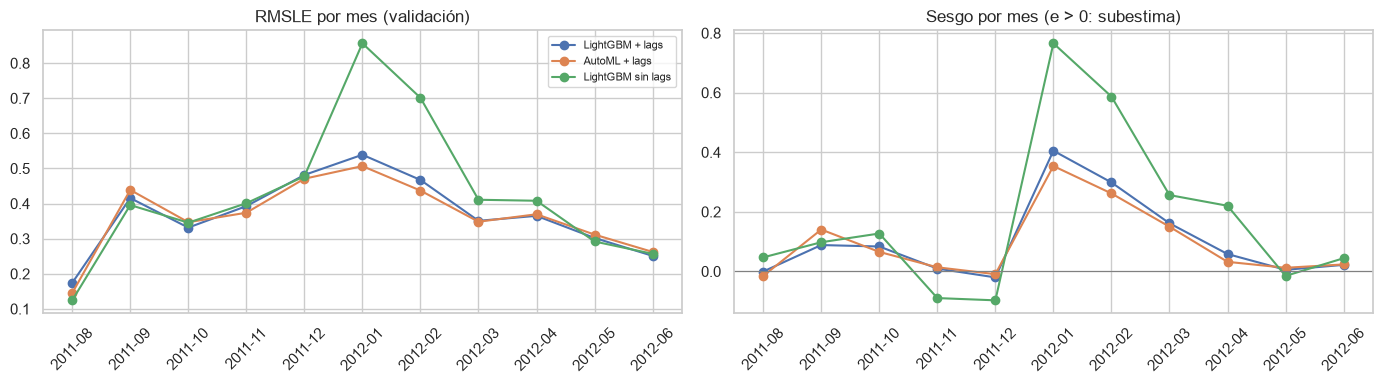

In [14]:
def por_grupo(o, col):
    g = o.groupby(col, observed=True)["e"]
    return pd.DataFrame({"n": g.size(), "RMSLE": g.apply(lambda s: float(np.sqrt((s ** 2).mean()))), "sesgo": g.mean()})

mensual = pd.concat({k: por_grupo(o, "mes") for k, o in R.items()}, axis=1)
display(mensual.round(3))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
meses = [str(m) for m in mensual.index]
for k in R:
    ax[0].plot(meses, mensual[(k, "RMSLE")].to_numpy(), marker="o", label=k); ax[1].plot(meses, mensual[(k, "sesgo")].to_numpy(), marker="o", label=k)
ax[0].set_title("RMSLE por mes (validación)"); ax[1].set_title("Sesgo por mes (e > 0: subestima)"); ax[1].axhline(0, color="gray", lw=0.8)
for a in ax: a.tick_params(axis="x", rotation=45)
ax[0].legend(fontsize=8); plt.tight_layout(); guardar(fig, "12_rmsle_por_mes"); plt.show()

### Punto de control 6

In [15]:
assert mensual.shape[0] == 11 and (mensual[("LightGBM + lags", "n")].sum() == 7300)
assert str(mensual.index.min()) == "2011-08" and str(mensual.index.max()) == "2012-06"
print(" 11 meses de validación (2011-08 a 2012-06; agosto solo tiene 22 horas), 7 300 horas.")

 11 meses de validación (2011-08 a 2012-06; agosto solo tiene 22 horas), 7 300 horas.


**Interpretación.**
- **El sesgo por tendencia está localizado en ene–mar de 2012.** Con lags, LightGBM subestima en +0.405 (ene), +0.299 (feb) y +0.161 (mar), mientras que de sep a dic de 2011 y de may a jun de 2012 el sesgo es ≈ 0 (entre −0.02 y +0.09). Sin lags es mucho peor: +0.766 en enero y +0.587 en febrero (RMSLE 0.856 y 0.701). Ene–feb son los meses del fold 3, cuyo train solo contiene 2011: el modelo no ha visto el salto de nivel de 2012.
- **Los lags corrigen cerca de la mitad de ese sesgo** (enero 0.766 → 0.405) porque aportan el nivel reciente, pero no todo.
- **RMSLE por mes (LightGBM + lags):** peor en enero (0.539), febrero (0.467) y diciembre (0.481); mejor en junio (0.251) y mayo (0.302). Esta curva mezcla estación y cantidad de train: cada mes cae en una sola ventana, así que **mes y fold están confundidos** y no se puede separar «invierno es difícil» de «el modelo había visto menos datos».
- **AutoML frente a LightGBM por mes:** AutoML es mejor en nov–mar (p. ej. enero 0.507 frente a 0.539), sobre todo en los meses del fold 3, y LightGBM es mejor en sep, oct, abr, may y jun; es el mismo patrón de los folds.
- Atención: ningún mes de la validación es julio ni agosto (agosto solo tiene 22 horas): **el sesgo del verano no puede medirse aquí**. Si el crecimiento de 2012 continúa en jul–dic, el test podría mostrar subestimación similar a la de ene–mar. Hipótesis: es lo primero que hay que mirar en el RMSLE mensual del Sprint 4.

### 4.3 Error por hora, día de la semana, `holiday` y clima adverso (`weathersit >= 3`)

Por tipo de condición (RMSLE | sesgo):


LightGBM + lags               AutoML + lags         \
                                    n  RMSLE  sesgo             n  RMSLE   
corte           valor                                                      
holiday         0                7063  0.390  0.114          7063  0.386   
                1                 237  0.582  0.013           237  0.560   
weathersit >= 3 0                6615  0.370  0.121          6615  0.365   
                1                 685  0.602  0.011           685  0.598   
workingday      0                2323  0.442  0.095          2323  0.442   
                1                4977  0.375  0.117          4977  0.367   

                             LightGBM sin lags                
                       sesgo                 n  RMSLE  sesgo  
corte           valor                                         
holiday         0      0.106              7063  0.477  0.191  
                1      0.033               237  0.716  0.082  
weathersit >= 3 0      0.116              6615  0.469  0.196  
                1     -0.016               685  0.625  0.113  
workingday      0      0.091              2323  0.543  0.181  
                1      0.109              4977  0.457  0.191

Por día de la semana (0 = domingo):


LightGBM + lags               AutoML + lags                \
                      n  RMSLE  sesgo             n  RMSLE  sesgo   
weekday                                                             
0                  1030  0.443  0.099          1030  0.442  0.091   
1                  1025  0.401  0.124          1025  0.404  0.104   
2                  1028  0.374  0.117          1028  0.360  0.105   
3                  1050  0.397  0.104          1050  0.381  0.101   
4                  1055  0.392  0.122          1055  0.381  0.114   
5                  1056  0.371  0.097          1056  0.363  0.105   
6                  1056  0.403  0.109          1056  0.412  0.103   

        LightGBM sin lags                
                        n  RMSLE  sesgo  
weekday                                  
0                    1030  0.550  0.202  
1                    1025  0.478  0.198  
2                    1028  0.466  0.193  
3                    1050  0.471  0.183  
4                    1055  0.472  0.185  
5                    1056  0.475  0.172  
6                    1056  0.487  0.183

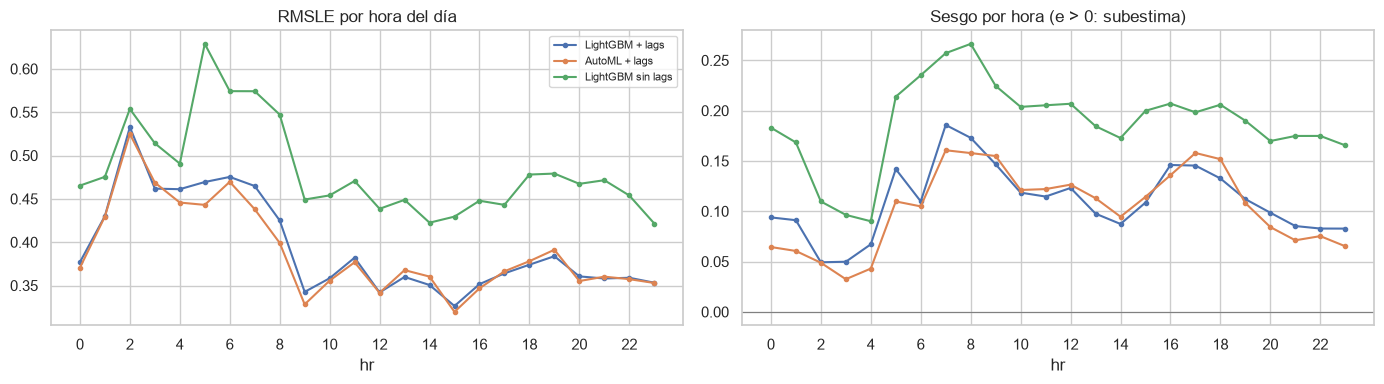

Horas con mayor RMSLE (LightGBM + lags): {2: 0.533, 6: 0.475, 5: 0.469, 7: 0.465, 3: 0.462}
Horas con menor RMSLE (LightGBM + lags): {15: 0.326, 12: 0.342, 9: 0.343}


In [16]:
cortes = {"hr": "hr", "weekday": "weekday", "holiday": "holiday", "weathersit >= 3": "adverso", "workingday": "workingday"}
tablas = {}
for nombre, col in cortes.items():
    tablas[nombre] = pd.concat({k: por_grupo(o, col) for k, o in R.items()}, axis=1)
print("Por tipo de condición (RMSLE | sesgo):")
resumen_cond = pd.concat({n: tablas[n] for n in ["holiday", "weathersit >= 3", "workingday"]}, names=["corte", "valor"])
display(resumen_cond.round(3))
print("Por día de la semana (0 = domingo):"); display(tablas["weekday"].round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for k in R:
    ax[0].plot(tablas["hr"].index, tablas["hr"][(k, "RMSLE")], marker="o", ms=3, label=k)
    ax[1].plot(tablas["hr"].index, tablas["hr"][(k, "sesgo")], marker="o", ms=3, label=k)
ax[0].set_title("RMSLE por hora del día"); ax[1].set_title("Sesgo por hora (e > 0: subestima)"); ax[1].axhline(0, color="gray", lw=0.8)
for a in ax: a.set_xlabel("hr"); a.set_xticks(range(0, 24, 2))
ax[0].legend(fontsize=8); plt.tight_layout(); guardar(fig, "13_error_por_hora"); plt.show()
h = tablas["hr"][("LightGBM + lags", "RMSLE")]
print("Horas con mayor RMSLE (LightGBM + lags):", h.sort_values(ascending=False).head(5).round(3).to_dict())
print("Horas con menor RMSLE (LightGBM + lags):", h.sort_values().head(3).round(3).to_dict())

### Punto de control 7

In [17]:
assert tablas["hr"].shape[0] == 24 and tablas["weekday"].shape[0] == 7
assert tablas["weathersit >= 3"][("LightGBM + lags", "n")].sum() == 7300
n_adv = int(tablas["weathersit >= 3"].loc[True, ("LightGBM + lags", "n")])
assert n_adv > 100, "muy pocas horas de clima adverso para concluir algo"
print(f" Cortes completos. Horas de validación con clima adverso: {n_adv} ({n_adv/7300:.1%}).")

 Cortes completos. Horas de validación con clima adverso: 685 (9.4%).


**Interpretación** (LightGBM + lags; AutoML es casi idéntico).
- **Hora del día:** el RMSLE es mayor en las horas de poca demanda (2:00 = 0.533, 6:00 = 0.475, 5:00 = 0.469, 7:00 = 0.465, 3:00 = 0.462) y menor a mediodía y por la tarde (15:00 = 0.326, 12:00 = 0.342, 9:00 = 0.343). Coincide con la heterocedasticidad de 4.1.
- **Clima adverso (`weathersit >= 3`, 685 horas, 9.4 %):** RMSLE 0.602 frente a 0.370 con clima normal, el **error más alto de todos los cortes**. El sesgo allí es ≈ 0 (+0.011), mientras que con buen clima el modelo subestima (+0.121): el problema en lluvia o nieve no es de nivel sino de **dispersión** (la demanda en esas horas es más impredecible). Sin lags el RMSLE en clima adverso es 0.625.
- **Feriados (`holiday = 1`, 237 horas):** 0.582 frente a 0.390; es el segundo corte con más error. Son pocas horas (≈ 10 días) y el modelo tiene pocos feriados en train.
- **Fin de semana o feriado (`workingday = 0`):** 0.442 frente a 0.375 en días laborables. Por día de la semana, el domingo es el peor (0.443) y los mejores son el viernes (0.371) y el martes (0.374).
- **Efecto de los lags en estos cortes:** mejoran todos (p. ej. feriados 0.716 → 0.582), pero el orden de dificultad no cambia: los casos más difíciles siguen siendo clima adverso, feriados, madrugada y fin de semana.
- Atención: con 237 horas de feriado y 685 de clima adverso, las cifras de esos cortes tienen más incertidumbre; no se calculó un intervalo.

## 5) Errores por cluster (hipótesis de Pardo, §5 punto 5 y §8.2)
Se regenera el modelo de Pardo (`src/clustering.py`, K-Means con k = 4 y entradas §5.1, sin el target) con su procedimiento del notebook 02: ajuste con todo train. `models/clustering_pardo.joblib` no viaja con git. Luego se asigna cada **hora de validación** a su cluster con `predict` y se calcula el RMSLE de cada modelo por cluster. **Los clusters son hipótesis, no categorías reales** (silueta 0.18: estructura débil). Atención: como se ajustan con todo train, las filas de validación participaron en el ajuste del clustering (no el target); no afecta al error del modelo supervisado, pero sí a lo «fuera de muestra» de la asignación.

Tamaño de los clusters en train: {0: 3495, 1: 3133, 2: 3373, 3: 3002}


,horas,cnt_media,hora_mediana,laborable,temp_c,lluvia_pct
cluster,,,,,,
0,3495,278.24,15.0,0.79,23.60,3.43
1,3133,137.94,7.0,1.00,17.90,12.93
2,3373,125.24,9.0,0.00,17.99,7.92
3,3002,117.83,19.0,1.00,19.16,11.33


RMSLE por cluster (validación):


modelo,LightGBM + lags,AutoML + lags,LightGBM sin lags
cluster,,,
0,0.282,0.282,0.393
1,0.426,0.407,0.508
2,0.464,0.464,0.564
3,0.392,0.390,0.456


Sesgo por cluster (e > 0: subestima):


modelo,LightGBM + lags,AutoML + lags,LightGBM sin lags
cluster,,,
0,0.121,0.120,0.200
1,0.130,0.123,0.198
2,0.091,0.084,0.184
3,0.099,0.086,0.168


Horas de validación por cluster: {0: 1831, 1: 1846, 2: 1926, 3: 1697}


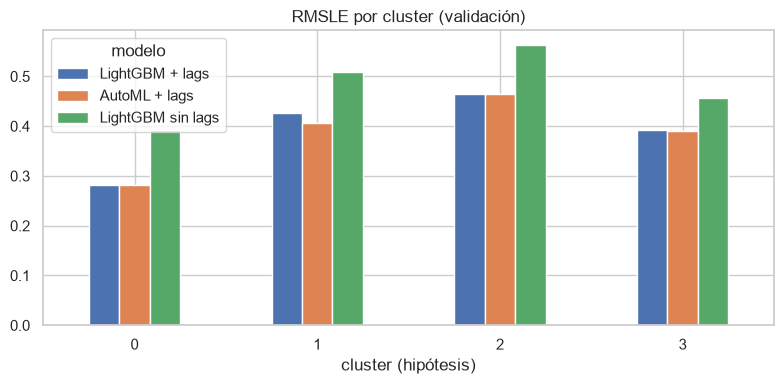

In [18]:
clu = build_clustering(K_ELEGIDO).fit(X_tr)
cluster = pd.Series(clu.predict(X_tr), index=X_tr.index, name="cluster")
tam = cluster.value_counts().sort_index()
print("Tamaño de los clusters en train:", tam.to_dict())

# Perfil de cada cluster (el target solo describe; no entró al clustering)
perfil = pd.DataFrame({"cluster": cluster, "cnt": y_tr, "hr": X_tr["hr"], "wd": X_tr["workingday"], "temp_c": X_tr["temp"] * 41,
                       "lluvia %": (X_tr["weathersit"] >= 3) * 100}).groupby("cluster").agg(
    horas=("cnt", "size"), cnt_media=("cnt", "mean"), hora_mediana=("hr", "median"), laborable=("wd", "mean"), temp_c=("temp_c", "mean"), lluvia_pct=("lluvia %", "mean"))
display(perfil.round(2))

filas = []
for k, o in R.items():
    o["cluster"] = cluster.loc[o.index].to_numpy()
    t = por_grupo(o, "cluster"); t["modelo"] = k; filas.append(t.reset_index())
por_cluster = pd.concat(filas).pivot(index="cluster", columns="modelo", values=["n", "RMSLE", "sesgo"])
orden = ["LightGBM + lags", "AutoML + lags", "LightGBM sin lags"]
print("RMSLE por cluster (validación):"); display(por_cluster["RMSLE"][orden].round(3))
print("Sesgo por cluster (e > 0: subestima):"); display(por_cluster["sesgo"][orden].round(3))
print("Horas de validación por cluster:", por_cluster["n"]["LightGBM + lags"].astype(int).to_dict())
fig, ax = plt.subplots(figsize=(8, 4))
por_cluster["RMSLE"][orden].plot.bar(ax=ax); ax.set_title("RMSLE por cluster (validación)"); ax.set_xlabel("cluster (hipótesis)"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); guardar(fig, "14_error_por_cluster"); plt.show()

### Punto de control 8: clusters reproducen los de Pardo

In [19]:
assert tam.to_dict() == {0: 3495, 1: 3133, 2: 3373, 3: 3002}, tam.to_dict()   # tamaños del notebook 02
assert K_ELEGIDO == 4 and set(VARIABLES) == {"hr_sin", "hr_cos", "temp", "hum", "windspeed", "workingday"}
assert "cnt" not in VARIABLES
assert por_cluster[("n", "LightGBM + lags")].sum() == 7300
print(" El clustering regenerado coincide con el de Pardo (tamaños 3495/3133/3373/3002); todas las horas de validación tienen cluster.")

 El clustering regenerado coincide con el de Pardo (tamaños 3495/3133/3373/3002); todas las horas de validación tienen cluster.


**Interpretación.** Los clusters se tratan como **hipótesis**: tienen silueta de 0.18 y explican solo el 17.5 % de la varianza (resumen de Pardo). El perfil regenerado coincide con el del notebook 02 (tamaños 3 495, 3 133, 3 373 y 3 002).

| Cluster (arquetipo según Pardo) | Demanda media | RMSLE LightGBM + lags | RMSLE AutoML + lags | RMSLE LightGBM sin lags |
| :--- | :---: | :---: | :---: | :---: |
| 0 · tarde cálida y seca | 278 | **0.282** | 0.282 | 0.393 |
| 1 · mañana laborable | 138 | 0.426 | 0.407 | 0.508 |
| 2 · no laborable | 125 | **0.464** | 0.464 | 0.564 |
| 3 · noche laborable | 118 | 0.392 | 0.390 | 0.456 |

- **El error se ordena de forma inversa a la demanda:** el cluster de más demanda (0) es el más fácil (0.282) y los de demanda media-baja son más difíciles; el peor es el **cluster 2 (horas no laborables, 0.464)**, coherente con el corte por `workingday` (0.442 frente a 0.375).
- **Los lags ayudan en los cuatro clusters** (caídas de 0.111, 0.082, 0.100 y 0.064 en los clusters 0, 1, 2 y 3), sin que el cluster 0 deje de ser el mejor.
- **AutoML y LightGBM solo difieren en el cluster 1** (0.407 frente a 0.426); en los demás son casi iguales. El sesgo es positivo en todos (0.084–0.130).
- **Uso responsable:** esto describe *dónde* falla el modelo, no es evidencia de que existan cuatro regímenes. Los clusters se ajustaron con todo train (sin usar el target), de modo que las ventanas de validación participaron en su ajuste; no afecta al error del modelo supervisado, pero la asignación no es estrictamente «fuera de muestra». Con un cluster que no incluye el clima adverso (Pardo, limitación 3), los resultados por cluster no sustituyen al corte por `weathersit`.

## 6) Interpretabilidad: permutation importance y SHAP (§8.3)
Los dos finalistas son `LGBMRegressor`, así que se usan las mismas herramientas. Para no ajustar nada con todo train, los modelos se ajustan **dentro de los folds 3, 4 y 5** (vía con lags) y se explican sobre la **ventana de validación de ese fold** (fuera de muestra). Se miran tres folds para ver si la importancia es estable: el fold 3 valida ene–mar de 2012 con train solo de 2011; los folds 4 y 5, abr–jun.

**Salvedad de variables correlacionadas:** `temp` y `atemp` tienen r = 0.99, `hr` y `workingday` forman `hr_workingday`, y `lag_24` y `lag_168` se parecen entre sí. La importancia de una variable correlacionada se reparte o se oculta en las demás, así que no se lee variable a variable sino por **grupos**, permutados en conjunto. La permutación se hace sobre las columnas crudas, antes del preprocesador, de modo que las variables derivadas se recalculan de forma coherente.

In [20]:
VAL = {k: v for k, v in enumerate(cv24.split(X_l), start=1)}

def ajustar_fold(nombre, k):
    i_tr, i_va = VAL[k]
    m = ajustar(construir(nombre, True)[0], X_l.iloc[i_tr], np.asarray(y_l, float)[i_tr], True)
    return m, X_l.iloc[i_va], np.asarray(y_l, float)[i_va]

GRUPOS = {"hora (hr)": ["hr"], "tipo de día (workingday, holiday, weekday)": ["workingday", "holiday", "weekday"],
          "temperatura (temp, atemp)": ["temp", "atemp"], "humedad": ["hum"], "viento": ["windspeed"], "clima (weathersit)": ["weathersit"],
          "estación y mes": ["season", "mnth"], "año (yr)": ["yr"], "lags (24 h y 168 h)": ["lag_24", "lag_168"],
          "lag_24": ["lag_24"], "lag_168": ["lag_168"], "dteday (control: no entra al modelo)": ["dteday"]}

def perm_grupos(m, Xv, yv, n_rep=5, seed=RANDOM_STATE):
    """Aumento del RMSLE al permutar cada grupo de columnas crudas (juntas, con la misma permutación de filas)."""
    rng = np.random.default_rng(seed); base = rmsle(yv, predecir_bicis(m, Xv, True)); filas = []
    for g, cols in GRUPOS.items():
        inc = []
        for _ in range(n_rep):
            Xp = Xv.copy(); idx = rng.permutation(len(Xv)); Xp[cols] = Xv[cols].iloc[idx].to_numpy()
            inc.append(rmsle(yv, predecir_bicis(m, Xp, True)) - base)
        filas.append({"grupo": g, "aumento RMSLE": float(np.mean(inc)), "std": float(np.std(inc, ddof=1))})
    return base, pd.DataFrame(filas).set_index("grupo")

PERM = {}
for nombre in ["LightGBM manual", "AutoML (FLAML → lgbm)"]:
    for k in (3, 4, 5):
        m, Xv, yv = ajustar_fold(nombre, k)
        base_k, PERM[(nombre, k)] = perm_grupos(m, Xv, yv)
        PERM[(nombre, k)].attrs["base"] = base_k
tab_perm = pd.concat({f"{n.split(' ')[0]} f{k}": v["aumento RMSLE"] for (n, k), v in PERM.items()}, axis=1)
display(tab_perm.sort_values("LightGBM f5", ascending=False).round(4))
print("RMSLE de cada fold (sin permutar):", {f"{n.split(' ')[0]} f{k}": round(v.attrs['base'], 4) for (n, k), v in PERM.items()})

,LightGBM f3,LightGBM f4,LightGBM f5,AutoML f3,AutoML f4,AutoML f5
grupo,,,,,,
hora (hr),0.6536,0.8102,0.7493,0.6472,0.6693,0.6704
lags (24 h y 168 h),0.4507,0.6232,0.6562,0.4801,0.7259,0.6814
lag_168,0.2425,0.4514,0.5200,0.1859,0.4343,0.4305
"tipo de día (workingday, holiday, weekday)",0.1704,0.1883,0.1803,0.1793,0.1593,0.1547
clima (weathersit),0.0382,0.0416,0.0581,0.0358,0.0492,0.0470
lag_24,0.0430,0.0719,0.0389,0.1308,0.1523,0.1063
humedad,0.0199,0.0554,0.0379,0.0217,0.0455,0.0349
viento,0.0088,0.0156,0.0079,0.0039,0.0088,0.0036
"temperatura (temp, atemp)",0.0402,0.0471,0.0069,0.0442,0.0473,0.0075


RMSLE de cada fold (sin permutar): {'LightGBM f3': 0.5044, 'LightGBM f4': 0.3572, 'LightGBM f5': 0.2782, 'AutoML f3': 0.4736, 'AutoML f4': 0.3581, 'AutoML f5': 0.2885}


### Punto de control 9: la permutación es coherente

In [21]:
# El control (dteday no entra al modelo con yr) no debe cambiar nada; y no hay mejoras grandes por azar
assert (tab_perm.loc["dteday (control: no entra al modelo)"].abs() < 1e-9).all()
assert np.isfinite(tab_perm.to_numpy()).all()
sin_efecto = tab_perm.index[(tab_perm.abs().max(axis=1) < 1e-4)].tolist()
print("Grupos sin efecto medible (< 0.0001) en ningún modelo/fold:", sin_efecto)
# El RMSLE de cada fold coincide con la tabla comparativa
for (n, k), v in PERM.items():
    assert abs(v.attrs["base"] - rm(C, n).iloc[k - 1]) < 1e-9, (n, k)
print(" La variable de control tiene importancia 0 y los RMSLE base coinciden con la sección 3.")

Grupos sin efecto medible (< 0.0001) en ningún modelo/fold: ['año (yr)', 'dteday (control: no entra al modelo)']
 La variable de control tiene importancia 0 y los RMSLE base coinciden con la sección 3.


### 6.2 SHAP (`TreeExplainer`) del LightGBM manual con lags
Contribución de cada variable a la predicción **en escala log** (`log1p(cnt)`) sobre la ventana de validación. Se agrupan las columnas derivadas por su origen (p. ej. las 48 de `hr_workingday`). La suma de las contribuciones más el valor base reproduce la predicción del modelo (aditividad, comprobada).

,fold 3,fold 4,fold 5
lag_168,0.417,0.477,0.546
hr,0.458,0.481,0.444
hr × workingday,0.241,0.260,0.229
temp_c,0.199,0.094,0.172
lag_24,0.142,0.154,0.151
yr,0.000,0.121,0.123
weathersit,0.089,0.082,0.087
hum,0.073,0.071,0.060
weekday,0.033,0.041,0.042
windspeed,0.024,0.024,0.026


Orden de importancia (fold 3 / 4 / 5): {3: ['hr', 'lag_168', 'hr × workingday', 'temp_c', 'lag_24'], 4: ['hr', 'lag_168', 'hr × workingday', 'lag_24', 'yr'], 5: ['lag_168', 'hr', 'hr × workingday', 'temp_c', 'lag_24']}


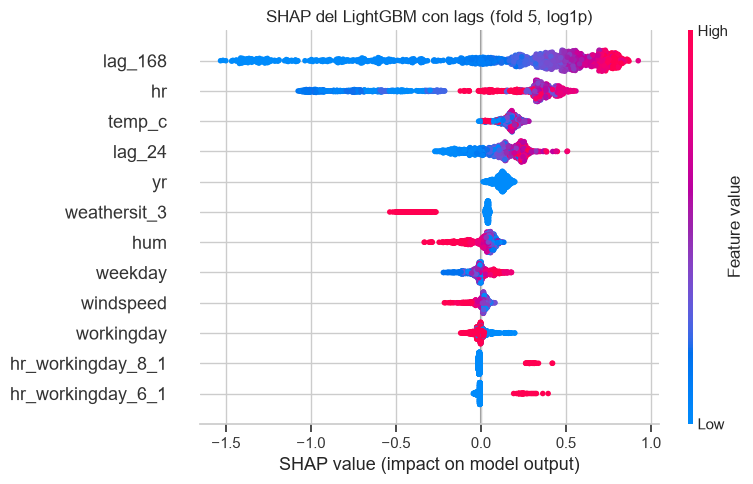

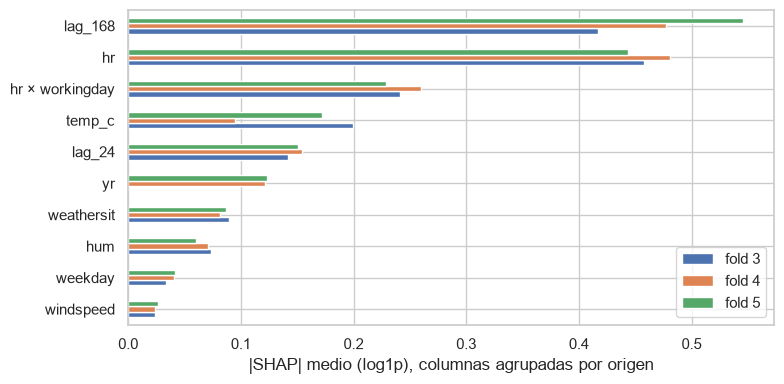

In [22]:
def origen(col):
    for pref, nom in [("hr_workingday_", "hr × workingday"), ("season_", "season"), ("weathersit_", "weathersit")]:
        if col.startswith(pref): return nom
    return col

SHAP = {}
for k in (3, 4, 5):
    m, Xv, yv = ajustar_fold("LightGBM manual", k)
    Zv = m.named_steps["prep"].transform(Xv); modelo = m.named_steps["modelo"]
    expl = shap.TreeExplainer(modelo); sv = expl.shap_values(Zv)
    assert np.allclose(sv.sum(1) + expl.expected_value, modelo.predict(Zv), atol=1e-4), "SHAP no es aditivo"
    abs_medio = pd.Series(np.abs(sv).mean(0), index=Zv.columns).groupby(origen).sum()
    SHAP[k] = {"abs": abs_medio, "sv": sv, "Z": Zv}
tab_shap = pd.DataFrame({f"fold {k}": v["abs"] for k, v in SHAP.items()}).sort_values("fold 5", ascending=False)
display(tab_shap.round(3).head(12))
print("Orden de importancia (fold 3 / 4 / 5):", {k: list(v['abs'].sort_values(ascending=False).index[:5]) for k, v in SHAP.items()})

fig = plt.figure(figsize=(8, 5)); shap.summary_plot(SHAP[5]["sv"], SHAP[5]["Z"], max_display=12, show=False, plot_size=None)
plt.title("SHAP del LightGBM con lags (fold 5, log1p)"); plt.tight_layout(); guardar(plt.gcf(), "15_shap_lightgbm"); plt.show()
fig, ax = plt.subplots(figsize=(8, 4)); tab_shap.head(10)[::-1].plot.barh(ax=ax); ax.set_xlabel("|SHAP| medio (log1p), columnas agrupadas por origen")
plt.tight_layout(); guardar(fig, "16_shap_por_grupo"); plt.show()

### Punto de control 10

In [23]:
assert tab_shap.shape[0] >= 10 and np.isfinite(tab_shap.to_numpy()).all()
tot = pd.DataFrame({f"fold {k}": v["abs"] / v["abs"].sum() for k, v in SHAP.items()})
assert np.allclose(tot.sum(), 1)
print(" SHAP aditivo en los 3 folds; la importancia relativa suma 1 en cada fold.")
print("Peso relativo (fracción del |SHAP| total) de lags y de hora x tipo de día:")
display(tot.loc[["lag_24", "lag_168", "hr × workingday", "hr", "temp_c", "yr"]].round(3))

 SHAP aditivo en los 3 folds; la importancia relativa suma 1 en cada fold.
Peso relativo (fracción del |SHAP| total) de lags y de hora x tipo de día:


,fold 3,fold 4,fold 5
lag_24,0.075,0.080,0.077
lag_168,0.219,0.249,0.280
hr × workingday,0.126,0.136,0.117
hr,0.240,0.251,0.227
temp_c,0.105,0.049,0.088
yr,0.000,0.063,0.063


**Interpretación.**
- **Qué usa el modelo (permutación y SHAP coinciden):** la **hora** (`hr`, junto con `hr × workingday`), los **lags** (sobre todo `lag_168`) y, en menor medida, el tipo de día, la temperatura, el clima y la humedad. En el SHAP del LightGBM con lags la hora aporta ≈ 23–25 % del |SHAP| total y `hr × workingday` ≈ 12–14 %, y los dos lags suman ≈ 29–36 % (`lag_168` 22–28 % y `lag_24` ≈ 8 %).
- **Permutación (aumento del RMSLE al romper el grupo):** `hr` 0.65–0.81 y lags 0.45–0.66 en LightGBM; en AutoML `hr` 0.65–0.67 y lags 0.48–0.73. El modelo **depende fuertemente de los lags**: si se rompe su información, el RMSLE de un fold sube entre 0.45 y 0.73 según el modelo y el fold.
- **`lag_168` (la misma hora de la semana anterior) importa más que `lag_24`** (la misma hora del día anterior) en LightGBM (permutación 0.24–0.52 frente a 0.04–0.07). AutoML reparte de forma distinta: usa más `lag_24` (0.11–0.15) y algo menos `lag_168` (0.19–0.43). Hipótesis: sugiere que el patrón semanal es la señal que más ayuda; no se probó causalmente.
- **La temperatura es poco importante con lags** (permutación 0.007 en el fold 5; 0.04 en los folds 3 y 4): los lags ya contienen parte del efecto del clima del mismo día de la semana pasada.
- **Año y tendencia:** `yr` no existe como señal en el fold 3 (train solo con 2011: importancia 0 por construcción) y vale ≈ 6 % del |SHAP| en los folds 4 y 5. La permutación de `yr` da 0 en los tres folds porque dentro de cada ventana de validación `yr` es constante (permutarlo no cambia nada): **es una limitación del método, no una prueba de que no importe**; el SHAP, que mide cómo usa el modelo el valor de `yr`, sí lo detecta.
- **Control:** `dteday` no entra al modelo y su importancia es exactamente 0 en todos los casos.
- Atención: **Salvedades:** (1) las variables correlacionadas reparten o enmascaran importancia (por eso se permutan en grupos: `temp` y `atemp` r = 0.99, los dos lags); (2) las importancias dependen de la ventana (p. ej. en el SHAP `temp_c` pesa más en el fold 3, de invierno, que en el 4); (3) SHAP y permutación describen **cómo usa el modelo los datos**, no relaciones causales; (4) SHAP está en escala log.

## 7) Propuesta de modelo final (§7.3 y §8.1) — decisión de Joan
Se comparan los **dos finalistas con lags** con evidencia de este notebook. `Random Forest`, `Ridge` y el baseline quedan descartados por rendimiento: en la vía con lags su RMSLE medio es 0.4125, 0.4766 y 0.5586, frente a 0.3905 y 0.3876. Se comprueba abajo en qué folds, si hay alguno, un tercer modelo supera a los dos finalistas.

In [24]:
lg, au = rm(C, "LightGBM manual"), rm(C, "AutoML (FLAML → lgbm)")
otros = pd.DataFrame({m: rm(C, m) for m in ["Baseline (hr, workingday)", "Ridge (splines × temp)", "Random Forest"]})
mejor_final = np.minimum(lg, au)
gana_otro = (otros.min(axis=1) < mejor_final).to_numpy()
print("Folds en que algún otro modelo supera al mejor de los dos finalistas:", [int(f) for f in gana_otro.nonzero()[0] + 1])
print("En esos folds:", otros[gana_otro].round(4).to_dict("index"), "| LightGBM manual:", lg[gana_otro].round(4).tolist(), "| AutoML:", au[gana_otro].round(4).tolist())

cfg_l = cfg_automl["con_lags"]["mejor_config"]
hojas_manual = P_LGBM["n_estimators"] * P_LGBM["num_leaves"]; hojas_auto = cfg_l["n_estimators"] * cfg_l["num_leaves"]
pd_ = lambda m, c: comparativa.query("modelo == @m and `vía` == @c").iloc[0]
a, b = pd_("LightGBM manual", C), pd_("AutoML (FLAML → lgbm)", C)
criterios = pd.DataFrame([
    ["RMSLE medio de validación (menor es mejor)", f"{a['RMSLE']:.4f}", f"{b['RMSLE']:.4f}", "AutoML (por 0.0029)"],
    ["Estabilidad: desviación entre folds", f"{a['± std folds']:.4f}", f"{b['± std folds']:.4f}", "AutoML"],
    ["Peor fold (fold 3)", f"{a['peor fold']:.4f}", f"{b['peor fold']:.4f}", "AutoML"],
    ["Folds en que gana al otro (de 5)", f"{int((lg < au).sum())}", f"{int((au < lg).sum())}", "LightGBM manual"],
    ["Diferencia agrupada, IC95% bootstrap por días (LGBM − AutoML)", f"{dif.loc[C, 'RMSLE agrupado LGBM − AutoML']:+.4f}", f"{dif.loc[C, 'IC95% bootstrap']}", "AutoML por poco (el IC roza el 0)"],
    ["Misma comparación sin lags (diferencia, IC95%)", f"{dif.loc[S, 'RMSLE agrupado LGBM − AutoML']:+.4f}", f"{dif.loc[S, 'IC95% bootstrap']}", "AutoML (el IC no incluye 0)"],
    ["Complejidad: árboles × hojas", f"{P_LGBM['n_estimators']} × {P_LGBM['num_leaves']} = {hojas_manual}", f"{cfg_l['n_estimators']} × {cfg_l['num_leaves']} = {hojas_auto}", "AutoML (menos hojas en total)"],
    ["Tiempo de ajuste de los 5 folds (s, esta máquina)", f"{a['tiempo 5 folds (s)']:.1f}", f"{b['tiempo 5 folds (s)']:.1f}", "AutoML"],
    ["Interpretabilidad (SHAP, permutación)", "igual: LGBMRegressor", "igual: LGBMRegressor", "empate"],
    ["Reproducibilidad de la búsqueda", "semilla fija, ~300 s (ficha 4)", "depende del tiempo de cómputo (fichas 14 y 14-corrección)", "LightGBM manual"],
    ["Reproducibilidad del modelo final", "parámetros en CONFIG", "configuración fijada en automl_config.json (se reproduce exacta, sección 2)", "empate"],
    ["Dependencias para usar el modelo", "ninguna extra", "ninguna extra (FLAML solo para repetir la búsqueda)", "empate"],
], columns=["criterio", "LightGBM manual + lags", "AutoML (FLAML) + lags", "ventaja"])
pd.set_option("display.max_colwidth", 80); display(criterios)

Folds en que algún otro modelo supera al mejor de los dos finalistas: [3]
En esos folds: {3: {'Baseline (hr, workingday)': 0.4949, 'Ridge (splines × temp)': 0.6958, 'Random Forest': 0.4595}} | LightGBM manual: [0.5044] | AutoML: [0.4736]


,criterio,LightGBM manual + lags,AutoML (FLAML) + lags,ventaja
0,RMSLE medio de validación (menor es mejor),0.3905,0.3876,AutoML (por 0.0029)
1,Estabilidad: desviación entre folds,0.0853,0.0697,AutoML
2,Peor fold (fold 3),0.5044,0.4736,AutoML
3,Folds en que gana al otro (de 5),3,2,LightGBM manual
4,"Diferencia agrupada, IC95% bootstrap por días (LGBM − AutoML)",+0.0053,"(-0.0005, 0.0105)",AutoML por poco (el IC roza el 0)
5,"Misma comparación sin lags (diferencia, IC95%)",+0.0125,"(0.0077, 0.0175)",AutoML (el IC no incluye 0)
6,Complejidad: árboles × hojas,524 × 31 = 16244,185 × 55 = 10175,AutoML (menos hojas en total)
7,"Tiempo de ajuste de los 5 folds (s, esta máquina)",3.3,1.7,AutoML
8,"Interpretabilidad (SHAP, permutación)",igual: LGBMRegressor,igual: LGBMRegressor,empate
9,Reproducibilidad de la búsqueda,"semilla fija, ~300 s (ficha 4)",depende del tiempo de cómputo (fichas 14 y 14-corrección),LightGBM manual


### Punto de control 11

In [25]:
assert len(gana_otro) == 5 and not gana_otro.all()
assert abs((lg.mean() - au.mean()) - 0.0029) < 6e-4
assert criterios.shape[0] == 12
print(" Tabla de criterios construida con las cifras de las secciones anteriores.")
print("Folds donde un tercer modelo supera al mejor finalista:", [int(f) for f in gana_otro.nonzero()[0] + 1] or "ninguno")

 Tabla de criterios construida con las cifras de las secciones anteriores.
Folds donde un tercer modelo supera al mejor finalista: [3]


**Interpretación y propuesta (decide Joan).**

*Descartados por rendimiento:* el baseline, Ridge y Random Forest. En la vía con lags tienen RMSLE medio de 0.5586, 0.4766 y 0.4125 frente a 0.3905 y 0.3876. Solo en el fold 3 un tercer modelo supera a ambos finalistas: Random Forest (0.4595 frente a 0.5044 y 0.4736), cuyo promedio queda 0.0220–0.0249 por detrás de ellos.

*Los dos finalistas son un empate práctico con la información disponible.* La diferencia (0.0029) es 7 veces menor que la desviación entre folds de la diferencia (0.0198), y el IC95 % por bootstrap de días ([−0.0005, 0.0105]) roza el cero. A favor de **AutoML**: mejor RMSLE medio, menor desviación entre folds, mejor peor fold (0.4736 frente a 0.5044), menos hojas en total (10 175 frente a 16 244), ajuste más rápido, y **consistencia con la vía sin lags**, donde gana con claridad (0.4405 frente a 0.4549, IC que excluye el 0, 4 de 5 folds). A favor de **LightGBM manual**: gana 3 de 5 folds cara a cara con lags, mejor RMSE y MAE en bicicletas con lags (63.2 y 40.6 frente a 64.4 y 41.0), y un procedimiento de búsqueda reproducible (semilla fija); la búsqueda de FLAML depende del tiempo de cómputo, como muestran las dos versiones de la ficha 14.

**Mi propuesta (no una decisión):** usar **LightGBM con `lag_24` + `lag_168` y la configuración que encontró AutoML** como modelo final, con el LightGBM manual como alternativa documentada. Razones: la dirección es la misma en las dos vías, es mejor en estabilidad y en el peor fold (que es lo que más importa si el test tiene un salto de nivel como el de ene–mar), y la debilidad de reproducibilidad de AutoML afecta a la *búsqueda* y no al *modelo*: la configuración está fijada y se reproduce exacta (sección 2). Si se prefiere la historia más sencilla de defender en la exposición (un tuning explícito con rangos y semillas, sin depender de FLAML), el LightGBM manual con lags es una elección igual de válida: con esta evidencia no se puede afirmar que uno sea mejor que otro.

**Antes de decidir, tener presente:**
1. **Decisión sobre los lags (condiciona todo):** el modelo con lags solo es válido bajo el horizonte «día siguiente» y depende de que el día anterior y la misma hora de la semana pasada estén completos. Los lags aportan ≈ 29–36 % del |SHAP| total: si fallan, el modelo se degrada mucho. Si el grupo decide no usar lags, el finalista es **AutoML sin lags** (0.4405), con clara ventaja sobre LightGBM (0.4549).
2. **Riesgo de tendencia:** el sesgo (subestimación) se concentra en ene–mar de 2012 y ningún fold valida jul–ago. El RMSLE mensual del test (Sprint 4) debe comprobarlo.
3. **Puntos débiles conocidos:** clima adverso (RMSLE 0.602), feriados (0.582), madrugada y fines de semana.
4. Ambos puntajes son optimistas (hiperparámetros elegidos sobre los mismos folds).